# 15 — Terrace edge with subsidence


## Imports and repository paths


In [1]:
from pathlib import Path
import sys

WORKING_DIR = Path.cwd().resolve()
ROOT = next((folder for folder in (WORKING_DIR, *WORKING_DIR.parents)
             if (folder / "utils/site_analysis.py").is_file()
             and (folder / "data/accelerometer").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its processing folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display
from utils import hvsr_tools as hv
from utils import plotting as hp
from utils import site_analysis as sa
from utils.analysis_figure import FIGURE_CONTROLS, make_analysis_figure


## Site and processing parameters


In [2]:
SITE = sa.SITE_BY_KEY['15_terrace_edge_subsidence']
PARAMS = sa.BASE_PARAMS
FIGURE_DIR = ROOT / "main/02_hvsr_processing/figures" / SITE.key
DATA_DIR = ROOT / "main/02_hvsr_processing/data" / SITE.key
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
display(pd.Series({
    "field_label": SITE.label,
    "session_id": SITE.session_id,
    "processing_parameters": PARAMS.to_dict(),
}, name="Analysis setup"))


field_label                               Borde de terraza con subsidencia
session_id                          CBUCF_titanSMA_1614_20230522_202000_01
processing_parameters    {'window_length_s': 120.0, 'overlap_pct': 0.0,...
Name: Analysis setup, dtype: object

## Recording and HVSR processing


In [3]:
analysis = sa.analyze_site(ROOT, SITE.key, PARAMS)
summary = sa.site_summary([analysis])
display(summary.round(3))
display(pd.Series(analysis.quality["metrics"], name="SESAME quality metrics"))


,site_key,session_id,field_label,f0_hz,A0,reliability_count,clarity_count,n_windows,thickness_vs_150_m,thickness_vs_250_m,thickness_vs_350_m
0,15_terrace_edge_subsidence,CBUCF_titanSMA_1614_20230522_202000_01,Borde de terraza con subsidencia,42.356,1.569,3,2,10,0.885,1.476,2.066


reliability_count                          3
clarity_count                              2
sesame_passed                          False
retained_fraction                        1.0
frequency_coverage_complete            False
fn_std_hz                          18.338253
sigma_a_at_peak                     1.163942
R1                                      True
R2                                      True
R3                                      True
C1                                      True
C2                                     False
C3                                     False
C4                                     False
C5                                     False
C6                                      True
time_blocks_complete                    True
block_global_max_deviation_pct     99.755604
block_tracked_max_deviation_pct    16.425526
Name: SESAME quality metrics, dtype: object

## Site analysis figure


{'pdf': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/15_terrace_edge_subsidence/15_terrace_edge_subsidence_analysis.pdf'),
 'svg': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/15_terrace_edge_subsidence/15_terrace_edge_subsidence_analysis.svg'),
 'png': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/15_terrace_edge_subsidence/15_terrace_edge_subsidence_analysis.png')}

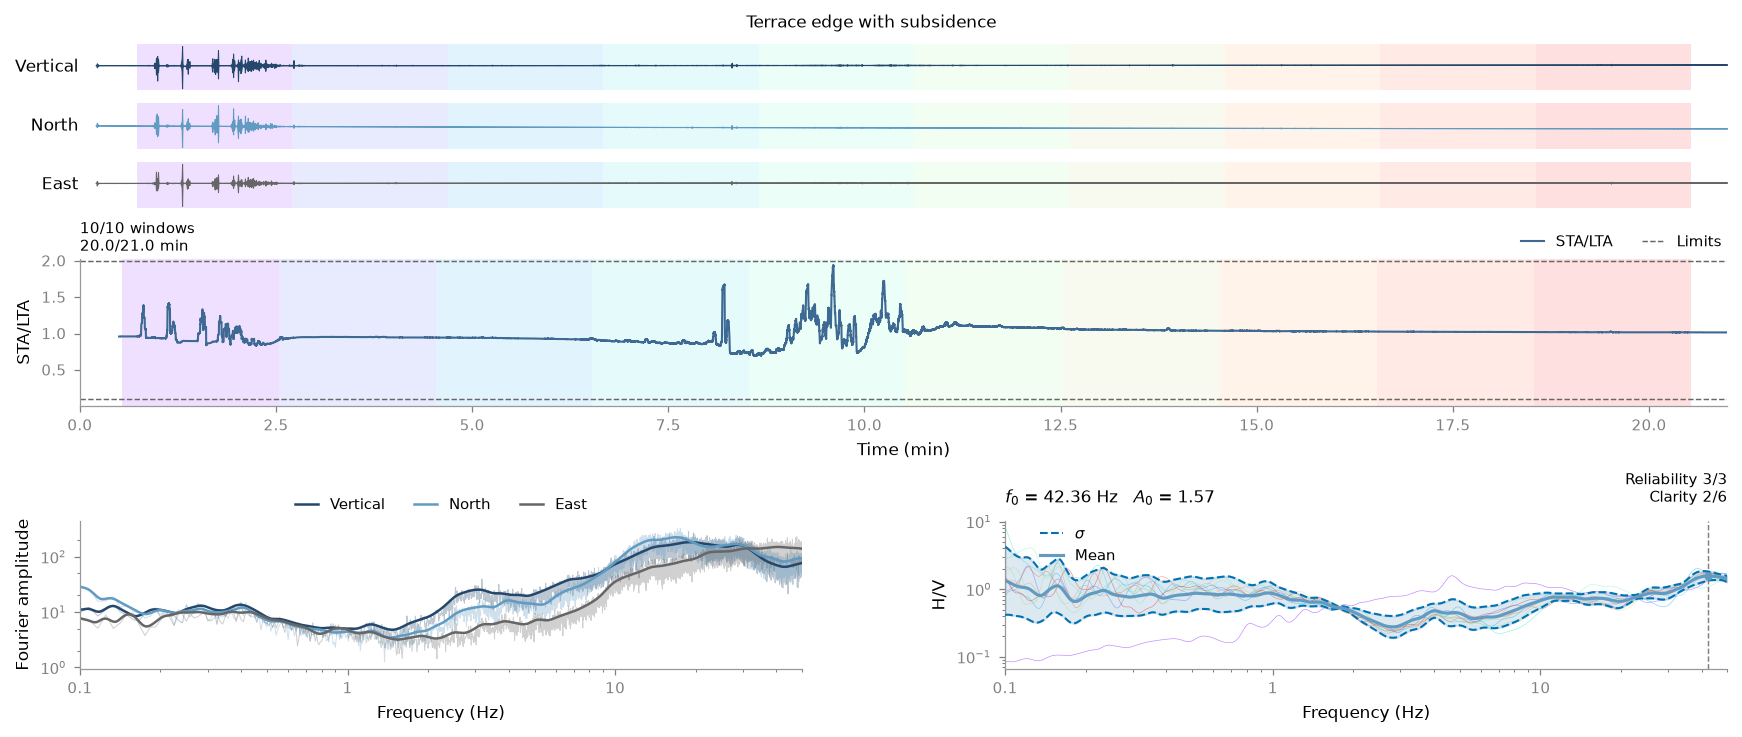

In [4]:
ANALYSIS_STYLE = hp.PaperStyle(width_in=11.5, font_size=8.0, tick_size=7.0,
                                   legend_size=7.0, dpi=300)
FOURIER_DATA = hv.component_fourier_data(analysis.record, analysis.result)
analysis_figure = make_analysis_figure(
    analysis.record,
    analysis.result,
    FOURIER_DATA.smoothed,
    FIGURE_CONTROLS,
    ANALYSIS_STYLE,
    show_windows=True,
    fourier_data=FOURIER_DATA,
)
analysis_figure.suptitle(SITE.figure_label, fontsize=ANALYSIS_STYLE.font_size)
figure_paths = hp.save_figure(
    analysis_figure,
    FIGURE_DIR / f"{SITE.key}_analysis",
    formats=("pdf", "svg", "png"),
    style=ANALYSIS_STYLE,
)
display(figure_paths)


## Data and diagnostics export


In [5]:
summary.to_csv(DATA_DIR / f"{SITE.key}_summary.csv", index=False)
data_paths = hv.save_outputs(
    analysis.result,
    DATA_DIR,
    prefix=SITE.key,
    extra={"field_label": SITE.label, "quality": analysis.quality["metrics"]},
)
display(data_paths)


{'curve': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/15_terrace_edge_subsidence/15_terrace_edge_subsidence_curve.csv'),
 'windows': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/15_terrace_edge_subsidence/15_terrace_edge_subsidence_windows.csv'),
 'summary': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/15_terrace_edge_subsidence/15_terrace_edge_subsidence_summary.json'),
 'selection': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/15_terrace_edge_subsidence/15_terrace_edge_subsidence_selection.csv')}